# TP3 : Clustering et word2vec (corpus CAMille)

**Partie 1 : clustering** des documents des années 1960 à 1969 (TF-IDF + KMeans), puis interprétation des clusters.
**Partie 2 : word2vec** entraîné sur les phrases du corpus (`sents.txt`), puis exploration avec `similarity`, `most_similar`.

## Installation (à lancer une seule fois)

In [1]:
!uv pip install gensim unidecode scikit-learn nltk wordcloud

Using Python 3.13.9 environment at: /home/minasema/tac/.venv
Checked 5 packages in 33ms


## Imports

In [2]:
import os
import re
import string
import collections
from pprint import pprint

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
from gensim.models.phrases import Phrases, Phraser
from unidecode import unidecode

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /home/minasema/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Configuration

- `ANNEES` : les années étudiées (décennie 1960 à 1969).
- `N_CLUSTERS` : nombre de clusters retenu (6).
- Les chemins sont détectés automatiquement, selon l'emplacement du notebook.

In [3]:
ANNEES = [1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969]
N_CLUSTERS = 6

# Dossier des textes CAMille
data_path = None
for chemin in ["../../data/txt/", "../data/txt/", "data/txt/"]:
    if os.path.isdir(chemin):
        data_path = chemin
        break
if data_path is None:
    raise FileNotFoundError(f"Dossier data/txt introuvable depuis {os.getcwd()}")

# Fichier de phrases pour word2vec (sents.txt, téléchargé sur l'UV)
sents_path = None
for chemin in ["../../data/sents.txt", "../data/sents.txt", "data/sents.txt"]:
    if os.path.isfile(chemin):
        sents_path = chemin
        break
if sents_path is None:
    raise FileNotFoundError("sents.txt introuvable : vérifiez qu'il est dans le dossier data")

temp_path = os.path.join(os.path.dirname(data_path.rstrip("/")), "tmp")
os.makedirs(temp_path, exist_ok=True)

print("Textes :", data_path)
print("Phrases :", sents_path)
print("Dossier de sortie :", temp_path)

Textes : ../../data/txt/
Phrases : ../../data/sents.txt
Dossier de sortie : ../../data/tmp


---

## Partie 1 : clustering des documents (1960–1969)

### Étape 1 : charger les textes

On garde les fichiers dont la date, dans le nom, est comprise entre 1960 et 1969.

In [4]:
files = []
for f in sorted(os.listdir(data_path)):
    for annee in ANNEES:
        if f"_{annee}-" in f:
            files.append(f)
            break

texts = [open(os.path.join(data_path, f), "r", encoding="utf-8").read() for f in files]

print(len(files), "documents")

1000 documents


### Étape 2 : vectoriser en TF-IDF

Le prétraitement retire d'abord la ponctuation (avec `str.maketrans`, car `translate` seul ne la supprime pas), puis ne garde que les mots alphabétiques de plus de 2 lettres. Les nombres et une partie des fragments d'OCR disparaissent ainsi des listes de mots.

In [5]:
def preprocessing(text):
    """Retire la ponctuation, puis garde les mots alphabétiques de plus de 2 lettres."""
    text = text.translate(str.maketrans("", "", string.punctuation))
    return [w for w in word_tokenize(text) if w.isalpha() and len(w) > 2]

vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words("french"),
    max_df=0.5,
    min_df=0.1,
    lowercase=True,
)
tfidf_vectors = vectorizer.fit_transform(texts)

print(tfidf_vectors.shape, "(documents, mots)")

/home/minasema/tac/.venv/lib/python3.13/site-packages/sklearn/feature_extraction/text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


(1000, 2565) (documents, mots)


### Étape 3 : lancer le KMeans

`random_state=0` et `n_init=10` rendent le résultat reproductible : chaque exécution donne les mêmes clusters.

In [6]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
clusters = km_model.fit_predict(tfidf_vectors)

clustering = collections.defaultdict(list)
for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

for label in sorted(clustering):
    print(f"Cluster {label} : {len(clustering[label])} documents")

Cluster 0 : 66 documents
Cluster 1 : 187 documents
Cluster 2 : 126 documents
Cluster 3 : 107 documents
Cluster 4 : 418 documents
Cluster 5 : 96 documents


### Étape 4 : mots caractéristiques de chaque cluster

Pour chaque cluster, on affiche les mots dont le poids moyen est le plus fort. Ces mots servent à juger si le cluster a du sens.

In [7]:
feature_names = vectorizer.get_feature_names_out()

for label in range(N_CLUSTERS):
    poids = km_model.cluster_centers_[label]
    top = [feature_names[i] for i in poids.argsort()[::-1][:15]]
    print(f"Cluster {label} : {', '.join(top)}")

Cluster 0 : musique, film, concert, programme, théâtre, orchestre, enf, admis, disques, beauxarts, journal, galeries, scolaire, opéra, œuvres
Cluster 1 : dem, rossel, ecrire, bilingue, prés, vitae, agence, engage, trav, ecr, curriculum, brux, dactylo, présenter, cherche
Cluster 2 : app, gar, villa, sdb, terr, jard, conf, louer, ares, cuis, mod, appart, faç, liv, vis
Cluster 3 : match, division, course, équipe, bat, championnat, placés, finale, classement, points, victoire, standard, joueurs, équipes, but
Cluster 4 : ministre, président, gouvernement, madame, monsieur, lieu, conseil, politique, millions, avril, général, mars, marché, novembre, octobre
Cluster 5 : état, fiat, peugeot, act, rem, cap, téléph, brux, achete, luxe, ford, créd, vend, garantie, rossel


### Étape 5 : visualisation des clusters

Les vecteurs sont réduits à deux dimensions avec la PCA. Les croix noires sont les centres des clusters. L'image est enregistrée dans `data/tmp/`.

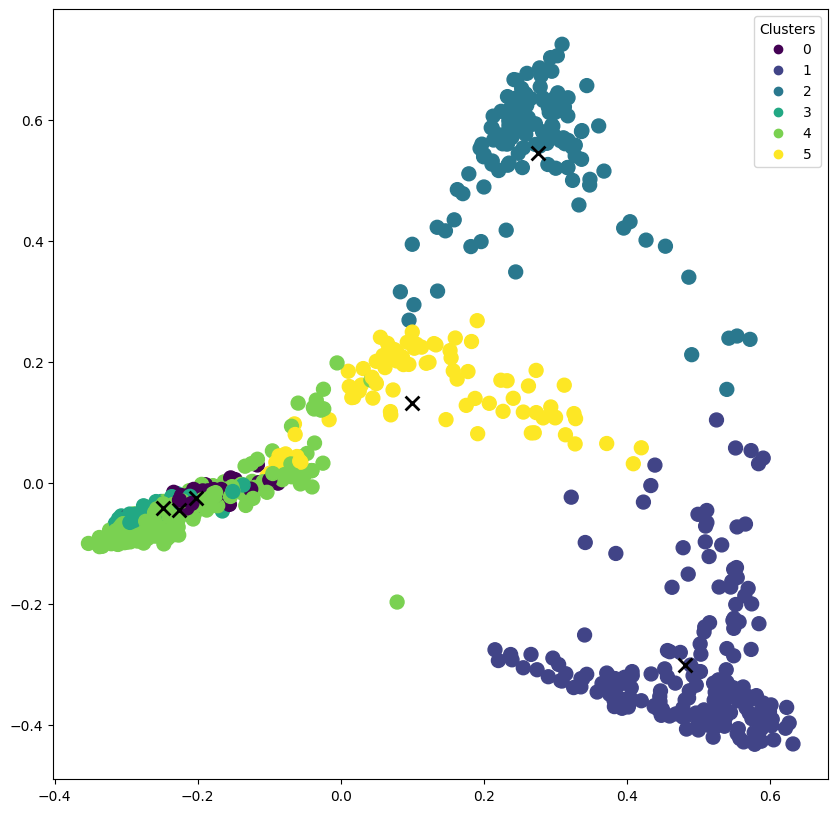

In [8]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10, 10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], marker="x", s=100, linewidths=2, color="black")

plt.legend(handles=scatter.legend_elements()[0], labels=list(np.unique(clusters)), title="Clusters")

plt.savefig(
    os.path.join(temp_path, f"tp3clusters_{N_CLUSTERS}.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Interprétation du clustering

J’ai appliqué un clustering par KMeans aux textes de 1960 à 1969 et j’ai retenu 6 clusters. J’ai fait ce choix parce que les mots de chaque cluster forment des thèmes lisibles, alors qu’avec 4 ou 3 clusters les thèmes se mélangent. Sur le graphique en deux dimensions, certains groupes semblent se séparer, tandis que d’autres se chevauchent. Cette projection ne conserve qu’une partie de l’information des vecteurs TF-IDF : je considère donc le graphique comme une illustration, et non comme une preuve de la séparation des clusters. Mon interprétation des thèmes repose sur les mots caractéristiques de chaque cluster.

---

## Partie 2 : word2vec sur le corpus de phrases

### Étape 1 : lire les phrases en streaming

La classe `MySentences` lit le fichier ligne par ligne, pour économiser la mémoire. Chaque ligne est découpée en mots, mise en minuscules et sans accents.

In [9]:
class MySentences(object):
    """Lit un fichier de phrases ligne par ligne et renvoie des listes de mots."""
    def __init__(self, filename):
        self.filename = filename

    def __iter__(self):
        for line in open(self.filename, encoding="utf-8", errors="backslashreplace"):
            yield [unidecode(w.lower()) for w in wordpunct_tokenize(line) if w.isalpha()]

sentences = MySentences(sents_path)

### Étape 2 : détecter les bigrammes et les trigrammes

Les expressions de deux ou trois mots qui apparaissent ensemble plus souvent que par hasard deviennent un seul mot pour word2vec (par exemple « grande_bretagne »).

In [10]:
bigram_phrases = Phrases(sentences)
bigram_phraser = Phraser(phrases_model=bigram_phrases)

trigram_phrases = Phrases(bigram_phraser[sentences])
trigram_phraser = Phraser(phrases_model=trigram_phrases)

corpus = list(trigram_phraser[bigram_phraser[sentences]])
print(len(corpus), "phrases")
print(corpus[:3])

12056370 phrases
[['mi', 'imnri', 'r', 'i', 'i', 'i', 'hmu', 'i', 'tx', 'l', 'marche', 'tenu', 'hors', 'villa', 'la'], ['u', 'a', 'ete', 'vaain', 'si', 'teicj', 'm', 'races_indigenes', 'de', 'fr'], ['a', 'k', 'de']]


### Étape 3 : entraîner trois modèles

On fait varier `window` (taille du contexte) et `min_count` (nombre minimum d'apparitions d'un mot). Chaque modèle est sauvegardé dans `data/tmp/`.

In [11]:
configurations = [
    {"window": 3, "min_count": 5},
    {"window": 5, "min_count": 5},
    {"window": 5, "min_count": 10},
]

modeles = {}
for cfg in configurations:
    nom = f"w{cfg['window']}_m{cfg['min_count']}"
    modele = Word2Vec(
        corpus,
        vector_size=32,
        window=cfg["window"],
        min_count=cfg["min_count"],
        workers=4,
        epochs=5,
    )
    modele.save(os.path.join(temp_path, f"{nom}.model"))
    modeles[nom] = modele
    print(nom, "→", len(modele.wv), "mots dans le vocabulaire")

w3_m5 → 467932 mots dans le vocabulaire
w5_m5 → 467932 mots dans le vocabulaire
w5_m10 → 287434 mots dans le vocabulaire


### Étape 4 : comparer les modèles (essais-erreurs)

On compare les voisins les plus proches du mot « ministre » dans chaque modèle.

In [12]:
for nom, modele in modeles.items():
    if "ministre" in modele.wv:
        voisins = [mot for mot, score in modele.wv.most_similar("ministre", topn=5)]
        print(f"{nom} : {', '.join(voisins)}")
    else:
        print(f"{nom} : « ministre » absent du vocabulaire")

w3_m5 : premier_ministre, ministre_des_finances, chancelier, ministere, negus
w5_m5 : premier_ministre, chancelier, ministre_des_finances, benes_ministre, ministre_adjoint
w5_m10 : premier_ministre, ministre_des_finances, chancelier, ministere, president


### Étape 5 : charger le modèle retenu

Le modèle retenu est `w5_m5` : ses voisins de « ministre » sont des fonctions de l'appareil politique et administratif.

In [13]:
MEILLEUR = "w5_m5"
model = Word2Vec.load(os.path.join(temp_path, f"{MEILLEUR}.model"))
print("Modèle retenu :", MEILLEUR)

Modèle retenu : w5_m5


### Étape 6 : explorer avec `similarity`

Plus la valeur est proche de 1, plus les deux mots sont proches dans le corpus.

In [14]:
for a, b in [("ministre", "roi"), ("paris", "londres"), ("belgique", "france")]:
    if a in model.wv and b in model.wv:
        print(f"similarity({a}, {b}) = {model.wv.similarity(a, b):.3f}")
    else:
        print(f"{a} ou {b} absent du vocabulaire")

similarity(ministre, roi) = 0.713
similarity(paris, londres) = 0.886
similarity(belgique, france) = 0.912


### Étape 7 : explorer avec `most_similar`

In [16]:
for mot in ["ministre", "paris", "football"]:
    if mot in model.wv:
        print(mot, "-", [m for m, s in model.wv.most_similar(mot, topn=5)])
    else:
        print(mot, "absent du vocabulaire")

ministre - ['premier_ministre', 'chancelier', 'ministre_des_finances', 'benes_ministre', 'ministre_adjoint']
paris - ['rome', 'londres', 'strasbourg', 'new_york', 'lyon']
football - ['championnat', 'tournoi', 'hockey', 'criterium', 'cross_country']


### Conclusion sur word2vec

J’ai entraîné trois modèles word2vec sur les phrases du corpus, en faisant varier la taille de la fenêtre (3 ou 5) et le seuil d’apparition minimal (5 ou 10). Le modèle retenu est w5_m5. Je l’ai choisi parce que ses voisins de « ministre » (premier ministre, chancelier, ministre des finances, ministre adjoint) désignent des fonctions de gouvernement. Je n’ai pas retenu w5_m10 : son vocabulaire est plus petit (287 434 mots contre 467 932), et ses voisins sont presque les mêmes.

Les similarités confirment en partie ce que le modèle a appris. « Belgique » et « France » sont les plus proches (0,912), puis « Paris » et « Londres » (0,886). « Ministre » et « roi » sont plus éloignés (0,713) : ces deux mots n’ont pas le même usage. Pour « Paris », les voisins sont surtout des grandes villes, dont New York, grâce au bigramme. Pour « football », les voisins (championnat, tournoi, hockey, cyclisme) relèvent du sport.